# PROYECTO 11.

Modelo para predecir permanencia de los clientes para el banco Beta Bank

## 1. Descarga y preparación de los datos

In [49]:
# Descarga de librerias requeridas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from sklearn.metrics import f1_score, classification_report, accuracy_score, roc_curve, roc_auc_score

# Descarga de datos
data = pd.read_csv('/datasets/Churn.csv')
print('Forma del dataset (Filas, Columnas): ',data.shape)
print()
print('Información general del dataset: ', data.info())
print()
print('Vistazo general del dataset: ', data.head(10))
print()
print('Datos duplicados en el dataset: ', data.duplicated().sum())
print()
print('Descripción del tipo de datos en el dataset: ', data.describe())


Forma del dataset (Filas, Columnas):  (10000, 14)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB
Información general del dataset:  None

Vis

#### Observaciones

El dataset tiene en total 10000 entradas de clientes con 14 columnas de datos:
- 'RowNumber' es basicamente una columna de seguimiento del dataset cuya significancia en el modelo a entrenar resulta inaportante debido a que es solo un dato ordinal en el juego de datos.
- 'CustomerID' es un número de identificación del cliente que tampoco aportaría un valor a tener en cuenta en el modelo a entrenar y su dato afectaría la eficacia del modelo.
- 'Surname' contiene el apellido del cliente, tampoco aporta al modelo a entrenar.
- 'CreditScore' contiene una calificación de crédito y permite entender si un cliente podrá o no cumplir con sus obligaciones financieras. Esta columna debe tenerse en cuenta en el modelo por su influencia en las predicciones, ya sea porque un cliente con bajo CreditScore pueda abandonar el banco sabiendo que no obtendrá un préstamo facilmente, o un cliente con alto CreditScore puede ser seducido por otros bancos.
- 'Geography' tiene el país de residencia del cliente. Inicialmente no parece ser una columna que pueda afectar el modelo, pero debe evaluarse con detenimiento.
- 'Gender' cotiene el sexo del cliente. Esta columna puede modificarse a valores numéricos (0=Female, 1=Male), pero debe tenerse en cuenta en la categorización al momento de realizar el entrenamiento.
- 'Tenure' indica la antiguedad del cliente con el banco. Esta columna es importante para el modelo que se entrenará, y debe prestársele un interés particular ya que contiene 909 datos ausentes. Esto pueda deberse a problemas al momento de montar el juego de datos, o simplemente porque tiene una mayor antiguedad a la máxima establecida en el dataset.
  como no se tiene una razón definitiva para este valor ausente, estos datos faltantes se "completarán" a partir de la mediana de los datos, que si bien es muy similar a la media, se puede inferir que no se verán afectados por valores límite.
- 'Balance' es el Saldo de la cuenta. Se tendrá en cuenta en el modelo ya que puede determinar si un cliente abandona el banco al no tener un mayor saldo.
- 'NumOfProducts' es el número de productos que tiene con el banco, se tendrá en cuenta en el modelo.
- 'HasCrCard' indica si el cliente tiene o no tarjeta de crédito con el banco, valor a tener en cuenta en el modelo.
- 'IsActiveMember' indica si el cliente tiene o no actividad con sus productos en el banco. variable a tener en cuenta.
- 'EstimatedSalary' es el salario estimado del cliente. valor a tener en cuenta en el modelo.
- 'Exited' indica si el cliente sigue o no en el banco. Es nuestra característica objetivo sobre la cual trabajaremos el modelo.

In [50]:
# Adecuación columna 'Tenure'
data['Tenure'] = data['Tenure'].fillna(data['Tenure'].median())

print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB
None


#### Observaciones

Se Completan los 909 valores ausentes con el valor de la mediana. Ya se tiene un juego de datos completo para trabajar.

In [51]:
# Revisión inicial columnas 'Geography' y 'Gender'

geography = data['Geography'].value_counts()
print('Clientes por país: ')
print(geography)
print()

data_geography_exited = pd.crosstab(data['Geography'], data['Exited'], normalize='index')*100
print('Clasificación de clientes actuales y retirados por país: ')
print(data_geography_exited)
print()

gender = data['Gender'].value_counts()
print('Clientes por género: ')
print(gender)

data_gender_exited = pd.crosstab(data['Gender'], data['Exited'], normalize='index')*100
print('Claisificación de clientes actuales y retirados por género: ')
print(data_gender_exited)

Clientes por país: 
France     5014
Germany    2509
Spain      2477
Name: Geography, dtype: int64

Clasificación de clientes actuales y retirados por país: 
Exited             0          1
Geography                      
France     83.845233  16.154767
Germany    67.556796  32.443204
Spain      83.326605  16.673395

Clientes por género: 
Male      5457
Female    4543
Name: Gender, dtype: int64
Claisificación de clientes actuales y retirados por género: 
Exited          0          1
Gender                      
Female  74.928461  25.071539
Male    83.544072  16.455928


#### Observaciones
- Se encuentra que el listado de clientes de Beta Bank reside en los países de Francia, Alemania y España.
- Adicionalmente, se encuentra que los clientes de Alemania se han retirado en mayor proporción que los clientes de Francia y España.
- Adicionalmente, se encuentra una equidad en clientes por género, con una mayor tasa de retiro en clientes femeninos que masculinos.
- Ambas situaciones, tanto de país de residencia y género se deben tener en cuenta en los modelos.

In [52]:
# Adecuación columnas 'Geography' y 'Gender' aplicando OHE y evitando la trampa Dummy

data_processed = pd.get_dummies(data, columns=['Geography', 'Gender'], drop_first=True)
print(data_processed.head())
print()
print(data_processed.info())

   RowNumber  CustomerId   Surname  CreditScore  Age  Tenure    Balance  \
0          1    15634602  Hargrave          619   42     2.0       0.00   
1          2    15647311      Hill          608   41     1.0   83807.86   
2          3    15619304      Onio          502   42     8.0  159660.80   
3          4    15701354      Boni          699   39     1.0       0.00   
4          5    15737888  Mitchell          850   43     2.0  125510.82   

   NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Exited  \
0              1          1               1        101348.88       1   
1              1          0               1        112542.58       0   
2              3          1               0        113931.57       1   
3              2          0               0         93826.63       0   
4              1          1               1         79084.10       0   

   Geography_Germany  Geography_Spain  Gender_Male  
0                  0                0            0  
1         

#### Observaciones

Se ha aplicado la técnica OHE, y el retiro de la columna redundante para las categorías 'Geography' y 'Gender'. En este momento se tiene un dataset de 15 columnas y 10000 datos para construir el modelo.

Se debe particionar este juego de datos en conjunto de Entrenamiento, validación y de prueba. Se tomará el 60% de los datos para entrenamiento, 20% para validación y 20% para prueba final.

In [53]:
# Definición de Features y Target
features = data_processed.drop(['RowNumber', 'CustomerId', 'Surname', 'Exited'], axis=1)

target = data_processed['Exited']

# Partición del juego de datos en set de entrenamiento, set de validación y set de prueba

features_train, features_split, target_train, target_split = train_test_split(features, target, test_size=0.4, random_state=792604)
features_valid, features_test, target_valid, target_test = train_test_split(features_split, target_split, test_size=0.5, random_state=792604)

features_train = features_train.copy()
features_valid = features_valid.copy()
features_test = features_test.copy()

## 2. Examen de equilibrio de clases y entrenamiento inicial del modelo

In [54]:
# Evaluación inicial del equilibrio de clases

exited = target.value_counts()/100
print(exited)

0    79.63
1    20.37
Name: Exited, dtype: float64


#### Observaciones

Se encuentra que un 20% de los clientes en el dataset se han retirado del banco. Esto puede llegar a desviar los resultados del modelo una vez entrenado.

Como se tienen datos de tipo numérico, se procede a entrenar el modelo bajo un esquema de bosque aleatorio con 100 arboles y una profundidad de 10. Se toman estos indicadores teniendo en cuenta que son numeros robustos para un entrenamiento del modelo.

Valor F1:  0.5463108320251177

Precisión:  0.8555

              precision    recall  f1-score   support

           0       0.86      0.98      0.91      1576
           1       0.82      0.41      0.55       424

    accuracy                           0.86      2000
   macro avg       0.84      0.69      0.73      2000
weighted avg       0.85      0.86      0.84      2000



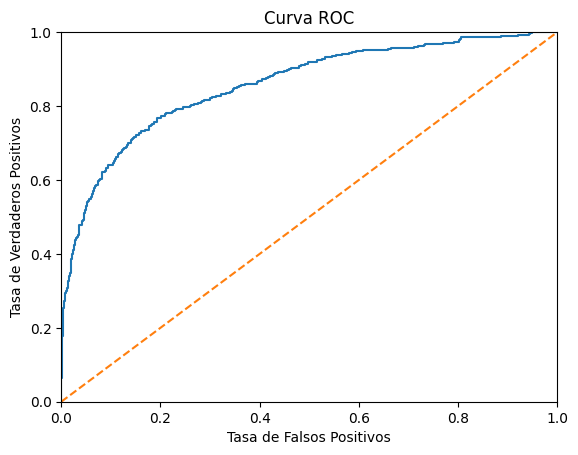

Área bajo la curva ROC:  0.8571392227755962


In [55]:
# Entrenamiento del modelo de bosque aleatorio con 100 arboles de 10 unidades de profundidad

model = RandomForestClassifier(random_state=792604, n_estimators=100, max_depth=10)
model.fit(features_train, target_train)
predicted_valid = model.predict(features_valid)

# Métricas para este modelo:
score = f1_score(target_valid, predicted_valid)
print('Valor F1: ', score)
print()
accuracy = accuracy_score(target_valid, predicted_valid)
print('Precisión: ', accuracy)
print()
print(classification_report(target_valid, predicted_valid))

# Curva ROC:
# Probabilidades para el set de validación
prob_valid = model.predict_proba(features_valid)
prob_valid_one = prob_valid[:, 1]
fpr, tpr, threshold = roc_curve(target_valid, prob_valid_one)

# Gráfica
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC')
plt.show()

# Área de la curva ROC
auc_roc = roc_auc_score(target_valid, prob_valid_one)
print('Área bajo la curva ROC: ', auc_roc)

#### Observaciones

Se ha entrenado un modelo de Bosque Aleatorio, con 100 arboles de profundidad 10, estos hiperparámetros son robustos para definir respuesta del modelo. Dicho entrenamiento muestra:
- Una exactitud del 85.55 que aparentemente no es un valor despreciable.
- Teniendo en cuenta que nuestro modelo se encuentra desbalanceado hacía la continuidad de los clientes, el modelo obviamente predecirá un 78.8% de permanencia de los clientes.
- El reporte del modelo entrega sin embargo un Recall de 0.41 para la clase 1, esto significa que el modelo escasamente podría predecir que 41 de cada 100 personas se retirarían del banco, un valor muy bajo de predicción.
- Nuestro F1 de 0.546, este valor nos indica que debemos mejorar el ajuste de clases para mejorar la predicción del modelo, especialmente teniendo en cuenta que el modelo lo favorece el alto porcentaje de clientes que permanecen en el banco.
- Si bien, la curva ROC muestra un alejamiento de la curva del modelo aleatorio, aun hay margen de mejora para el entrenamiento del modelo. la curva se "estabiliza" cerca de los valores [0.2, 0.8], valores que coinciden con el desequilibrio de clases
- El valor del área bajo la curva es de 0.857, lo que confirma la oportunidad de mejora.

## 3. Optimización del modelo

Para este punto se realizará lo siguiente:
1. Ajustar el peso de clase y entrenar modelos de bosque aleatorio y regresión logística.
2. Hacer un Sobremuestreo duplicando datos y entrenar modelos de bosque aleatorio y regresión logística.
3. Hacer un submuestreo del 20% de los datos y entrenar modelos de bosque aleatorio y regresión logística.

En todos los casos se calculará el valor de F1, y el AUC-ROC para determinar el modelo más confiable.

Valor F1:  0.5175834084761046
              precision    recall  f1-score   support

           0       0.90      0.75      0.81      1576
           1       0.42      0.68      0.52       424

    accuracy                           0.73      2000
   macro avg       0.66      0.71      0.67      2000
weighted avg       0.79      0.73      0.75      2000



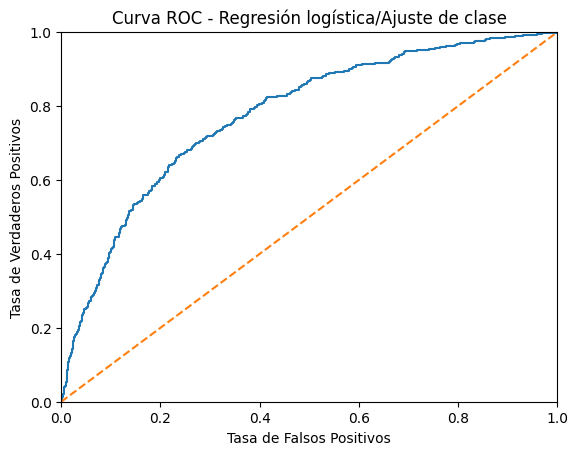

Área bajo la curva ROC:  0.7758700675222681


In [56]:
# Modelo de Regresión logística con ajuste de peso de clase:

#Escalado de características
numeric = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
scaler = StandardScaler()
scaler.fit(features_train[numeric])
features_train.loc[:, numeric] = scaler.transform(features_train[numeric])
features_valid.loc[:, numeric] = scaler.transform(features_valid[numeric])
features_test.loc[:, numeric] = scaler.transform(features_test[numeric])

modellrwb = LogisticRegression(random_state=792604, solver='liblinear', class_weight='balanced')
modellrwb.fit(features_train, target_train)
predicted_valid_lrwb = modellrwb.predict(features_valid)
print('Valor F1: ', f1_score(target_valid, predicted_valid_lrwb))
print(classification_report(target_valid, predicted_valid_lrwb))

# Curva ROC:
# Probabilidades para el set de validación
prob_valid_lrwb = modellrwb.predict_proba(features_valid)
prob_valid_one_lrwb = prob_valid_lrwb[:, 1]
fpr, tpr, threshold = roc_curve(target_valid, prob_valid_one_lrwb)

# Gráfica
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC - Regresión logística/Ajuste de clase')
plt.show()

# Área de la curva ROC
auc_roc_lrwb = roc_auc_score(target_valid, prob_valid_one_lrwb)
print('Área bajo la curva ROC: ', auc_roc_lrwb)


#### Observaciones

- El método de ajuste de clase utilizando un modelo de regresión logística presenta un comportamiento menor al que se observó con el Bosque Aleatorio sin tener en cuenta el desequilibrio de clases.
- El valor F1 se reduce a 0.518, el cual es un valor que se aleja del valor mínimo establecido para aceptar el modelo, y aunque el Recall aumenta, la precisión al hacer un ajuste de clase se reduce a 0.42. 
- El área bajo la curva ROC también se reduce a 0.776 y la curva como tal trata de ajustarse mas a la curva del modelo aleatorio, otra razón que termina justificando el valor F1.
- Se debe tener en cuenta que al realizar el ajuste de clase se "castiga" también el peso de la probabilidad de permanecer en el banco.


Valor F1:  0.6360424028268551
              precision    recall  f1-score   support

           0       0.90      0.90      0.90      1576
           1       0.64      0.64      0.64       424

    accuracy                           0.85      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.85      0.85      0.85      2000



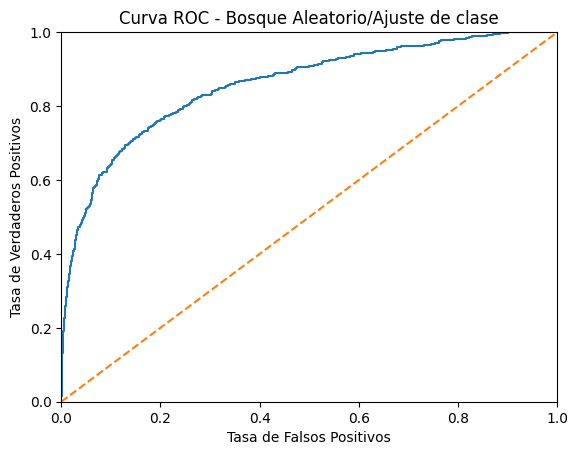

Área bajo la curva ROC:  0.8582331673211379


In [57]:
# Modelo de Bosque Aleatorio con ajuste de peso de clase:

modelrfwb = RandomForestClassifier(random_state=792604, n_estimators=100, max_depth=10, class_weight='balanced')
modelrfwb.fit(features_train, target_train)
predicted_valid_rfwb = modelrfwb.predict(features_valid)
print('Valor F1: ', f1_score(target_valid, predicted_valid_rfwb))
print(classification_report(target_valid, predicted_valid_rfwb))

# Curva ROC:
# Probabilidades para el set de validación
prob_valid_rfwb = modelrfwb.predict_proba(features_valid)
prob_valid_one_rfwb = prob_valid_rfwb[:, 1]
fpr, tpr, threshold = roc_curve(target_valid, prob_valid_one_rfwb)

# Gráfica
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC - Bosque Aleatorio/Ajuste de clase')
plt.show()

# Área de la curva ROC
auc_roc_rfwb = roc_auc_score(target_valid, prob_valid_one_rfwb)
print('Área bajo la curva ROC: ', auc_roc_rfwb)

#### Observaciones

- El método de ajuste de clase utilizando un modelo de bosque aleatorio presenta un mejor ajuste al observado con el modelo entrenado sin considerar el desequilibrio de clases.
- El valor F1 aumenta un valor de 0.637, el cual ya puede aceptarse como un modelo válido.
- La precisión disminuye para la precisión de abandono del banco, pero el Recall mejora para la misma predicción.
- El área bajo la curva ROC aparentemente no presenta un cambio apreciable. pero la curva como tal si presenta un codo más cercano a valores de [0.25, 0.85], lo cual indica un mejor comportamiento al ajustar el desequilibrio de clases.

Valor F1:  0.5159574468085106
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1576
           1       0.41      0.69      0.52       424

    accuracy                           0.73      2000
   macro avg       0.66      0.71      0.66      2000
weighted avg       0.79      0.73      0.75      2000



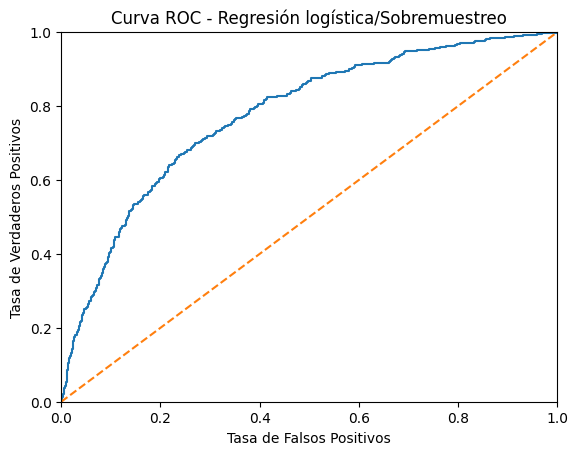

Área bajo la curva ROC:  0.7758910185805957


In [58]:
# Modelo de regresión logística con sobremuestreo:

#División del set
def upsample(features, target, repeat):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    #Duplicado de las observaciones y generación de un nuevo set de datos
    features_upsampled = pd.concat([features_zeros] + [features_ones]*repeat)
    target_upsampled = pd.concat([target_zeros]+[target_ones]*repeat)

    #Mezclado de los datos
    features_upsampled, target_upsampled = shuffle(features_upsampled, target_upsampled, random_state= 792604)

    return features_upsampled, target_upsampled

features_us,  target_us = upsample(features_train, target_train, 4)

#Aplicación del modelo
modellrus = LogisticRegression(random_state=792604, solver='liblinear')
modellrus.fit(features_us, target_us)
predicted_valid_lrus = modellrus.predict(features_valid)
print('Valor F1: ', f1_score(target_valid, predicted_valid_lrus))
print(classification_report(target_valid, predicted_valid_lrus))

# Curva ROC:
# Probabilidades para el set de validación
prob_valid_lrus = modellrus.predict_proba(features_valid)
prob_valid_one_lrus = prob_valid_lrus[:, 1]
fpr, tpr, threshold = roc_curve(target_valid, prob_valid_one_lrus)

# Gráfica
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC - Regresión logística/Sobremuestreo')
plt.show()

# Área de la curva ROC
auc_roc_lrus = roc_auc_score(target_valid, prob_valid_one_lrus)
print('Área bajo la curva ROC: ', auc_roc_lrus)

#### Observaciones

- El método de sobremuestreo utilizando un modelo de regresión logística muestra un comportamiento indeseado.
- El valor de F1 final es de 0.516 lo cual es bajo para el estandar establecido de 0.59.
- En este caso el sobremuestreo con un valor de 4 muestra que se desequilibra hacia el otro extremo de las predicciones.
- Se observa un ligero aumento del Recall (0.69) pero se reduce el valor de precisión drásticamente (0.41). 
- El área bajo la curva ROC también decrece a un dato de 0.776, más cercano a la curva del modelo aleatorio.

Valor F1:  0.6299045599151643
              precision    recall  f1-score   support

           0       0.91      0.86      0.89      1576
           1       0.57      0.70      0.63       424

    accuracy                           0.83      2000
   macro avg       0.74      0.78      0.76      2000
weighted avg       0.84      0.83      0.83      2000



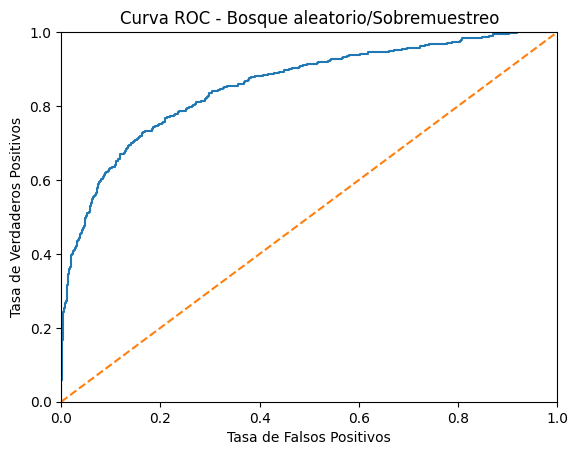

Área bajo la curva ROC:  0.8546550258595921


In [59]:
# Modelo de bosque aleatorio con sobremuestreo:

modelrfus = RandomForestClassifier(random_state=792604, n_estimators=100, max_depth=10)
modelrfus.fit(features_us, target_us)
predicted_valid_rfus = modelrfus.predict(features_valid)
print('Valor F1: ', f1_score(target_valid, predicted_valid_rfus))
print(classification_report(target_valid, predicted_valid_rfus))

# Curva ROC:
# Probabilidades para el set de validación
prob_valid_rfus = modelrfus.predict_proba(features_valid)
prob_valid_one_rfus = prob_valid_rfus[:, 1]
fpr, tpr, threshold = roc_curve(target_valid, prob_valid_one_rfus)

# Gráfica
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC - Bosque aleatorio/Sobremuestreo')
plt.show()

# Área de la curva ROC
auc_roc_rfus = roc_auc_score(target_valid, prob_valid_one_rfus)
print('Área bajo la curva ROC: ', auc_roc_rfus)

#### Observaciones

- El método de sobremuestreo utilizando un modelo de bosque aleatorio se adapta a las necesidades del ejercicio.
- Se supera el umbral de valor F1 con un dato de 0.630. así mismo, El recall aumenta a 0.70 pero la precisión se disminuye a 0.57
- El área bajo la curva ROC apenas se ve afectada y se obtiene un valor de 0.855, lo que permite inferir que este método de Bosque aleatorio presenta un buen nivel de predicción comparado con la regresión logística.

Valor F1:  0.5161290322580644
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1576
           1       0.42      0.68      0.52       424

    accuracy                           0.73      2000
   macro avg       0.66      0.71      0.66      2000
weighted avg       0.79      0.73      0.75      2000



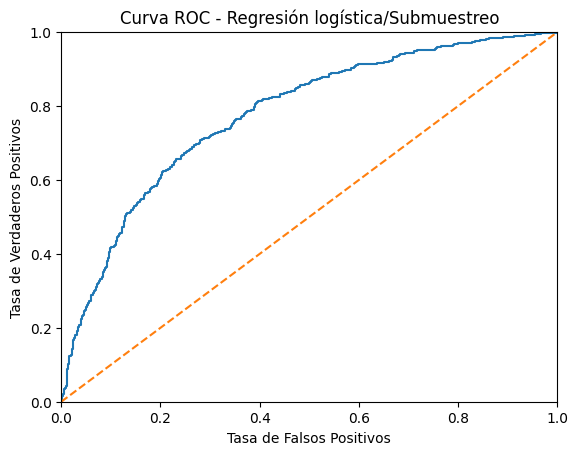

Área bajo la curva ROC:  0.7757278996264726


In [60]:
# Modelo de regresión logística con submuestreo:

#División del set
def downsample(features, target, fraction):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    #Duplicado de las observaciones y generación de un nuevo set de datos
    features_downsampled = pd.concat([features_zeros.sample(frac=fraction, random_state=792604)] + [features_ones])
    target_downsampled = pd.concat([target_zeros.sample(frac=fraction, random_state=792604)] + [target_ones])

    #Mezclado de los datos
    features_downsampled, target_downsampled = shuffle(features_downsampled, target_downsampled, random_state= 792604)

    return features_downsampled, target_downsampled

features_ds,  target_ds = downsample(features_train, target_train, 0.25)

#Aplicación del modelo
modellrds = LogisticRegression(random_state=792604, solver='liblinear')
modellrds.fit(features_ds, target_ds)
predicted_valid_lrds = modellrds.predict(features_valid)
print('Valor F1: ', f1_score(target_valid, predicted_valid_lrds))
print(classification_report(target_valid, predicted_valid_lrds))

# Curva ROC:
# Probabilidades para el set de validación
prob_valid_lrds = modellrds.predict_proba(features_valid)
prob_valid_one_lrds = prob_valid_lrds[:, 1]
fpr, tpr, threshold = roc_curve(target_valid, prob_valid_one_lrds)

# Gráfica
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC - Regresión logística/Submuestreo')
plt.show()

# Área de la curva ROC
auc_roc_lrds = roc_auc_score(target_valid, prob_valid_one_lrds)
print('Área bajo la curva ROC: ', auc_roc_lrds)

#### Observaciones

- El método de submuestreo aplicado a un modelo de regresión logística sigue sin ser satisfactorio para los datos que se tienen. Se redujo el grupo de datos de clientes que permanecen en el banco en un 25%.
- El valor F1 final fue de 0.516 que es similar al obtenido con el sobremuestreo. En ambos casos, no se supera el umbral establecido de 0.59.
- El Recall aumento a valores de 0.68 y la precisión se reduce a 0.42, lo que explica que no aumente el valor F1.
- El área ROC también llega a 0.776, lo que muestra un modelo inadecuado.


Valor F1:  0.6033834586466165
              precision    recall  f1-score   support

           0       0.92      0.80      0.86      1576
           1       0.50      0.76      0.60       424

    accuracy                           0.79      2000
   macro avg       0.71      0.78      0.73      2000
weighted avg       0.83      0.79      0.80      2000



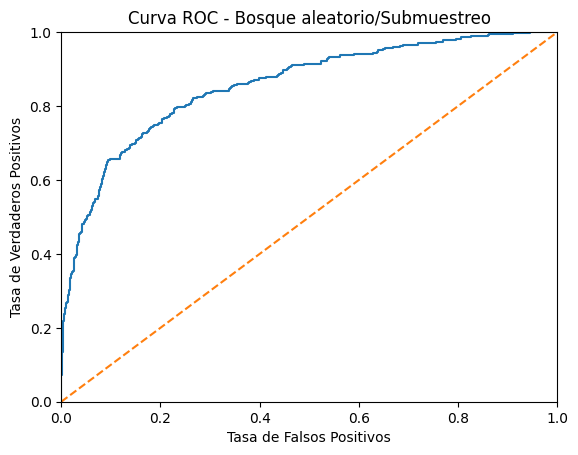

Área bajo la curva ROC:  0.855840257159276


In [61]:
# Modelo de bosque aleatorio con submuestreo:

modelrfds = RandomForestClassifier(random_state=792604, n_estimators=100, max_depth=10)
modelrfds.fit(features_ds, target_ds)
predicted_valid_rfds = modelrfds.predict(features_valid)
print('Valor F1: ', f1_score(target_valid, predicted_valid_rfds))
print(classification_report(target_valid, predicted_valid_rfds))

# Curva ROC:
# Probabilidades para el set de validación
prob_valid_rfds = modelrfds.predict_proba(features_valid)
prob_valid_one_rfds = prob_valid_rfds[:, 1]
fpr, tpr, threshold = roc_curve(target_valid, prob_valid_one_rfds)

# Gráfica
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC - Bosque aleatorio/Submuestreo')
plt.show()

# Área de la curva ROC
auc_roc_rfds = roc_auc_score(target_valid, prob_valid_one_rfds)
print('Área bajo la curva ROC: ', auc_roc_rfds)

#### Observaciones

- El método de submuestreo utilizando un modelo de bosque aleatorio se adapta a las necesidades del ejercicio, pero el valor F1 decrece en comparación que los metodos de ajuste de clase y sobremuestreo
- Se supera el umbral de valor F1 con un dato de 0.603. así mismo, El recall aumenta a 0.76 pero la precisión se disminuye a 0.50. Este último valor de precisión puede terminar afectando el valor F1.
- El área bajo la curva ROC apenas se ve afectada y se obtiene un valor de 0.856, lo que permite inferir que este método de Bosque aleatorio presenta un buen nivel de predicción comparado con la regresión logística, aplicando las 3 técnicas de manejo de desequilibrio de clases.


### Consideraciones finales

Actualmente se tienen los siguientes resultados de valores F1, Recall (1), precisión (1) y Área ROC para los modelos entrenados:

-----------------------------------------------------------------
| Métrica             | F1    | Recall | Precisión | Área ROC   |
-----------------------------------------------------------------
| BosqAlea sin ajuste | 0.546 |  0.41  |    0.82   |  0.857     |  
---------------------------------------------------------------
| RegrLog ajuste      | 0.518 |  0.68  |    0.42   |  0.776     |
-----------------------------------------------------------------
| BosqAlea ajuste     | 0.636 |  0.64  |    0.64   |  0.858     |
-----------------------------------------------------------------
| RegrLog sobremuest  | 0.516 |  0.69  |    0.41   |  0.776     |
-----------------------------------------------------------------
| BosqAlea sobremuest | 0.630 |  0.70  |    0.57   |  0.855     |
-----------------------------------------------------------------
| RegrLog submuest    | 0.516 |  0.68  |    0.42   |  0.775     |
-----------------------------------------------------------------
| BosqAlea submuest   | 0.603 |  0.76  |    0.50   |  0.856     |
-----------------------------------------------------------------

Basado en estos resultados, se encuentra que los modelos de bosque aleatorio que incluyen una técnica de ajuste para manejar el desequilibrio de los datos presentan mejores resultados que los obtenidos para la regresión logística.
Los 3 modelos de bosque aleatorio con técnicas de ajuste superan el umbral solicitado de 0.59 para el valor F1. 
Basado en lo anterior, teniendo en cuenta además que el área ROC en los 3 casos es similar a 0.85, quedan el Recall y la precisión para tomar la decisión final. si bien el bosque aleatorio con submuestreo tiene el recall mas alto, presenta una reducción considerable en la precisión, lo que finalmente afecta el valor F1. El bosque aleatorio con sobremuestreo por otro lado, tiene el valor F1 alto (0.63) y sostiene un alto Recall manteniendo una precisión equilibrada de 0.57.

Por lo anterior, se tomará el Bosque Aleatorio con sobremuestreo para hacer la validación final.

## 4. Prueba final

Antes de aplicar el modelo de Bosque aleatorio con sobremuestreo, se realiza un análisis de sensibilidad para obtener los mejores parámetros de número de árboles y profundidad para ahorrar tiempo de computo.

In [62]:
# Definición hiperparámetros iniciales:
best_depth_rf = 0
best_f1_rf = 0
best_est_rf = 0

#Aplicación del modelo
#Aplicando a numero de arboles entre 5 y 100 variando cada 5
for est in range(5, 100, 5):
    #Aplicando a produndidad de arboles entre 1 y 10
    for depth in range(1,11):
        model_rf = RandomForestClassifier(random_state=792604, n_estimators=est, max_depth=depth)
        model_rf.fit(features_us, target_us)
        prediction_rf = model_rf.predict(features_valid)
        f1_rf = f1_score(target_valid, prediction_rf)

        #Definición de mejores parámetros
        if f1_rf > best_f1_rf:
            best_depth_rf = depth
            best_f1_rf = f1_rf
            best_est_rf = est

#Datos finales
print('Datos para modelo de Bosque aleatorio con sobremuestreo:')
print()
print('Número de arboles:', best_est_rf)
print()
print('profundidad del árbol:', best_depth_rf)
print()
print('Valor F1 del módelo:', best_f1_rf)
print()

if best_f1_rf > 0.59:
    print('El modelo de bosque aleatorio supera el umbral de valor F1!')
else:
    print('El modelo de bosque aleatorio no supera el umbral de valor F1 y debe descartarse')


Datos para modelo de Bosque aleatorio con sobremuestreo:

Número de arboles: 50

profundidad del árbol: 10

Valor F1 del módelo: 0.6328042328042329

El modelo de bosque aleatorio supera el umbral de valor F1!


Valor F1:  0.6095661846496108
              precision    recall  f1-score   support

           0       0.92      0.85      0.89      1610
           1       0.54      0.70      0.61       390

    accuracy                           0.82      2000
   macro avg       0.73      0.78      0.75      2000
weighted avg       0.85      0.82      0.83      2000



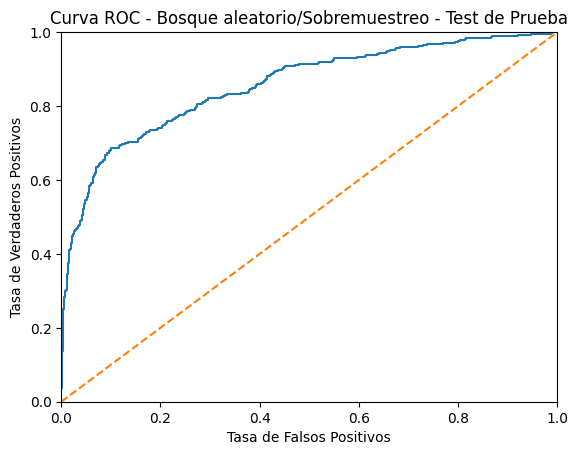

Área bajo la curva ROC:  0.8558432871476349


In [63]:
# Aplicación del Bosque Aleatorio con sobremuestreo al set de prueba:
model_rf = RandomForestClassifier(random_state=792604, n_estimators=best_est_rf, max_depth=best_depth_rf)
model_rf.fit(features_us, target_us)

predicted_test_rfus = model_rf.predict(features_test)
print('Valor F1: ', f1_score(target_test, predicted_test_rfus))
print(classification_report(target_test, predicted_test_rfus))

# Curva ROC:
# Probabilidades para el set de prueba
prob_test_rfus = model_rf.predict_proba(features_test)
prob_test_one_rfus = prob_test_rfus[:, 1]
fpr, tpr, threshold = roc_curve(target_test, prob_test_one_rfus)

# Gráfica
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC - Bosque aleatorio/Sobremuestreo - Test de Prueba')
plt.show()

# Área de la curva ROC
auc_roc_rfus_test = roc_auc_score(target_test, prob_test_one_rfus)
print('Área bajo la curva ROC: ', auc_roc_rfus_test)


#### Observaciones
- Se realiza la aplicación del modelo de bosque aleatorio con sobremuestreo en el juego de datos de prueba.
- Se evaluan diferentes hiperparámetros para obtener el mejor modelo, encontrando un bosque de 50 arboles y 10 unidades de profundidad.
- Como se ha observado, las métricas de evaluación presentan conformidad con los resultados obtenidos con el entrenamiento.
- El valor de F1 baja un poco pero sigue estando dentro del umbral establecido. un valor de 0.610 es aceptable para nuestro caso.
- El Recall sube a 0.70 pero la precisión baja a 0.54. Por ello es que se afecta el valor F1.
- La curva ROC finalmente se mantiene en valores de 0.856, lo que es una buena señal para el modelo.

## Conclusiones generales

- Se ha realizado un análisis de un grupo de datos de usuarios de Beta Bank para la obtenición de un modelo que permita predecir si un cliente se puede o no retirar del banco, debido a un aumento en el retiro de usuarios.

- Se efectuó un tratamiento adecuado al juego de datos para la obtención de data confiable y robusta para el entrenamiento del modelo.

- Se realizó una adecuación del conjunto de datos para tener disponibilidad de datos para el entrenamiento y validación de los modelos.

- Se realiza una evaluación de modelos de regresión logística y bosque aleatorio, considerando el desequilibrio de clases bajo 3 técnicas diferentes. Esta evaluación arrojó que un modelo de Bosque Aleatorio ajustando el desequilibrio con Sobremuestreo con un factor de repetición de 4 con un bosque de 50 arboles de 10 unidades de profundidad arroja los mejores resultados para el valor F1.

- En general los modelos de bosque aleatorio con ajustes de desequilibrio arrojan buenos resultados, sin embargo el sobremuestreo presenta la mejor relación de valor F1 con valores de precisión y recall aceptables. En todos los casos el área de la curva ROC es de 0.85.

- Se realiza la evaluación del modelo seleccionado con el grupo de prueba final y se corroboran los resultados obtenidos previamente.

- Finalmente se obtiene un modelo con un valor F1 del 61%, lo cual es un modelo moderado y equilibrado para las predicciones deseadas, donde se tienen en cuenta una buena relación de precisión y recall, identificando una buena parte de los clientes potenciales a retirar.
